# RoadScan — controlled YOLO comparison

This experiment preserves Sara’s exact v2 split: 8,999 training images from Japan, India and Czech Republic and 1,977 China MotorBike validation images. The team confirmed this dataset version.

We train COCO-initialized YOLO11s (native C2PSA attention) and YOLOv8s with the same seed, image size, optimizer, augmentation and training budget. Runs 14 and 17 are references on the same validation set. YOLO11s already contained attention in Run 14; this is a comparison of complete pipelines, not an isolated attention ablation. No improvement is guaranteed.

The 190 local images are NOT attached or accessed. Model and confidence selection use RDD validation only. A fixed RDD US comparison follows selection and is not used to select a model. Local evaluation is a separate, later step after model/configuration freeze; earlier local exposure remains a documented limitation.

Each section explains its code and interprets the actual outputs. Artifacts include audited manifests, configuration, training curves, validation comparisons, selected weights, frozen confidence, JSON and CSV results.

Architecture reference: https://github.com/ultralytics/ultralytics/blob/main/ultralytics/cfg/models/11/yolo11.yaml

In [1]:
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from IPython.display import display, Markdown
import json, hashlib, shutil, sys, subprocess, time, gc
import numpy as np
import pandas as pd
from PIL import Image
import yaml

display(Markdown("## 1. Audit the confirmed team split\nVerify every training/validation image and label, preserve country metadata, check exact cross-split pixel duplicates, and save a portable manifest. No local photographs are attached or read."))
subprocess.check_call([sys.executable,'-m','pip','install','-q','ultralytics==8.4.177'])
import torch, ultralytics
from ultralytics import YOLO
assert torch.cuda.is_available(), 'Enable GPU before running.'
CLASSES=['D00','D10','D20','D40']
OUT=Path('/kaggle/working/run23'); OUT.mkdir(exist_ok=True)
INPUT=Path('/kaggle/input')
attached=[p.name for p in INPUT.glob('*/*/*') if p.is_dir()]
assert not any('local-test' in s or 'my-photos' in s or s.startswith('22-roadscan') for s in attached), attached
BASE=INPUT/'notebooks/sarvii7/roadscan-03-sample9000-v2'
SOURCE=BASE/'sample9000'
assert SOURCE.is_dir(), 'Attach Sara sample9000 v2 output.'
original=(BASE/'sample9000_list.txt').read_text().splitlines()
assert len(original)==len(set(original))==8999
ROOT=Path('/kaggle/working/run23_team_data')
jobs=[]
for split,n in [('train',8999),('val',1977)]:
    ims={p.stem:p for p in (SOURCE/split/'images').glob('*.jpg')}
    lbs={p.stem:p for p in (SOURCE/split/'labels').glob('*.txt')}
    assert ims.keys()==lbs.keys() and len(ims)==n, (split,len(ims),len(lbs))
    if split=='train':
        assert set(ims)==set(original)
        assert Counter(s.split('_')[0] for s in ims)=={'Japan':4000,'India':3500,'Czech':1499}
    else: assert all(s.startswith('China_MotorBike_') for s in ims)
    for folder in ['images','labels']: (ROOT/split/folder).mkdir(parents=True,exist_ok=True)
    jobs.extend((split,s,ims[s],lbs[s]) for s in sorted(ims))
def audit_image(job):
    split,stem,ip,lp=job
    with Image.open(ip) as im:
        im.load(); w,h=im.size; pixelsha=hashlib.sha256(im.convert('RGB').tobytes()).hexdigest()
    raw=lp.read_text(); present=[0]*4; boxes=0
    for line in raw.splitlines():
        if not line.strip(): continue
        vals=list(map(float,line.split())); assert len(vals)==5 and np.isfinite(vals).all(), (stem,line)
        c,x,y,bw,bh=vals; assert c==int(c) and 0<=c<4 and bw>0 and bh>0
        assert min(x-bw/2,y-bh/2)>=-0.001 and max(x+bw/2,y+bh/2)<=1.001, (stem,vals)
        present[int(c)]=1; boxes+=1
    shutil.copy2(ip,ROOT/split/'images'/ip.name); shutil.copy2(lp,ROOT/split/'labels'/lp.name)
    return dict(split=split,stem=stem,country=stem.split('_')[0],width=w,height=h,boxes=boxes,empty=int(boxes==0),pixel_sha256=pixelsha,label_sha256=hashlib.sha256(lp.read_bytes()).hexdigest(),**dict(zip(CLASSES,present)))
records=[]
with ThreadPoolExecutor(max_workers=4) as pool:
    for i,row in enumerate(pool.map(audit_image,jobs),1):
        records.append(row)
        if i%2000==0: print('AUDITED',i,'/',len(jobs),flush=True)
manifest=pd.DataFrame(records)
assert not (manifest.groupby('pixel_sha256').split.nunique()>1).any(), 'Cross-split exact pixel duplicate: stop and review.'
manifest.to_csv(OUT/'data_manifest.csv',index=False)
DATA=ROOT/'data.yaml'; DATA.write_text(yaml.safe_dump(dict(path=str(ROOT),train='train/images',val='val/images',names=CLASSES)))
POLICY=dict(data_source='sarvii7/roadscan-03-sample9000-v2',source_version=360884073,seed=42,training_images=8999,validation_images=1977,local_images_used=False,local_final_test_locked=True,candidates=['yolo11s_c2psa','yolov8s'],initialization='official COCO only; no prior RoadScan checkpoint is used for initialization',selection='highest China validation mAP50-95; ties prefer lower validation inference time',confidence_selection='China validation only; maximize box macro-F1 subject to D40 recall >=0.90 when feasible; otherwise maximize D40 recall and flag floor unmet',test_policy='RDD US only after selection; no test-driven selection; local final evaluation is not called',attention='YOLO11s native C2PSA; full-pipeline comparison, not isolated attention ablation',known_limitations=['single seed','China development tuning is not independent accuracy','US results were inspected in earlier project experiments','local images were previously evaluated with old models; no access in this experiment'])
(OUT/'experiment_policy.json').write_text(json.dumps(POLICY,indent=2))
(OUT/'environment.json').write_text(json.dumps(dict(python=sys.version,torch=torch.__version__,ultralytics=ultralytics.__version__,gpu=torch.cuda.get_device_name(0),sample_manifest_sha256=hashlib.sha256((BASE/'sample9000_list.txt').read_bytes()).hexdigest()),indent=2))
display(manifest.groupby(['split','country'])[['empty']+CLASSES].agg(['count','sum']))
display(Markdown(f"**Audit interpretation:** All {len(manifest):,} training/validation images decoded and labels passed geometry checks. The exact 8,999-image training manifest and 1,977-image China validation split are preserved. Exact cross-split pixel duplicates were not found. Healthy/background images are retained. No local image source is attached. The experiment and selection rules are saved before training."))
print('RUN23_DATA_READY',flush=True)


## 1. Audit the confirmed team split
Verify every training/validation image and label, preserve country metadata, check exact cross-split pixel duplicates, and save a portable manifest. No local photographs are attached or read.

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
AUDITED 2000 / 10976
AUDITED 4000 / 10976
AUDITED 6000 / 10976
AUDITED 8000 / 10976
AUDITED 10000 / 10976


empty        D00         D10         D20         D40      
              count  sum count   sum count   sum count   sum count   sum
split country                                                           
train Czech    1499  427  1499   764  1499   300  1499   129  1499   154
      India    3500  500  3500  1012  3500    60  3500  1586  3500  1530
      Japan    4000  500  4000   989  4000  2240  4000  1741  4000  1390
val   China    1977   43  1977  1419  1977   738  1977   486  1977   164

**Audit interpretation:** All 10,976 training/validation images decoded and labels passed geometry checks. The exact 8,999-image training manifest and 1,977-image China validation split are preserved. Exact cross-split pixel duplicates were not found. Healthy/background images are retained. No local image source is attached. The experiment and selection rules are saved before training.

RUN23_DATA_READY


## 2. Train two controlled candidates
Fine-tune official COCO-initialized YOLO11s and YOLOv8s on the exact team training set. Both use 640 pixels, AdamW, cosine learning-rate decay, the same training augmentations and seed. Each run allows 60 epochs, patience 15 and a 1.5-hour cap checked at epoch boundaries. Actual completed epochs and training time are recorded; a time cap can make completed schedules differ. Validation selects each checkpoint. US/local data are not used for training or model selection.

### Train yolo11s_c2psa
Initialization is the official yolo11s.pt COCO model. No RoadScan 14/17 or published RDD checkpoint is loaded into this candidate.

New https://pypi.org/project/ultralytics/8.4.197 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/run23_team_data/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/38      5.03G      2.262      2.771      2.078         10        640: 100% ━━━━━━━━━━━━ 563/563 5.3it/s 1:45
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 62/62 4.0it/s 15.4s
                   all       1977       4650      0.298     0.0476     0.0311    0.00813

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/41      5.03G      2.209      2.688      2.025         10        640: 100% ━━━━━━━━━━━━ 563/563 5.3it/s 1:46
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 62/62 4.1it/s 15.0s
                   all       1977       4650      0.114      0.134     0.0594     0.0174

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/42      5.03G      2.156      2.585      1.963         17        640: 100% ━━━━━━━━━━━━ 563/563 5.3it/s 1:45
                 Class     Images  Instances      Box(

**Training interpretation:** yolo11s_c2psa completed 45 epochs in 91.3 minutes under the stated budget. Its best validation checkpoint is saved. Training loss alone is not evidence of generalization; compare the next section's validation metrics. Native C2PSA blocks: 1.

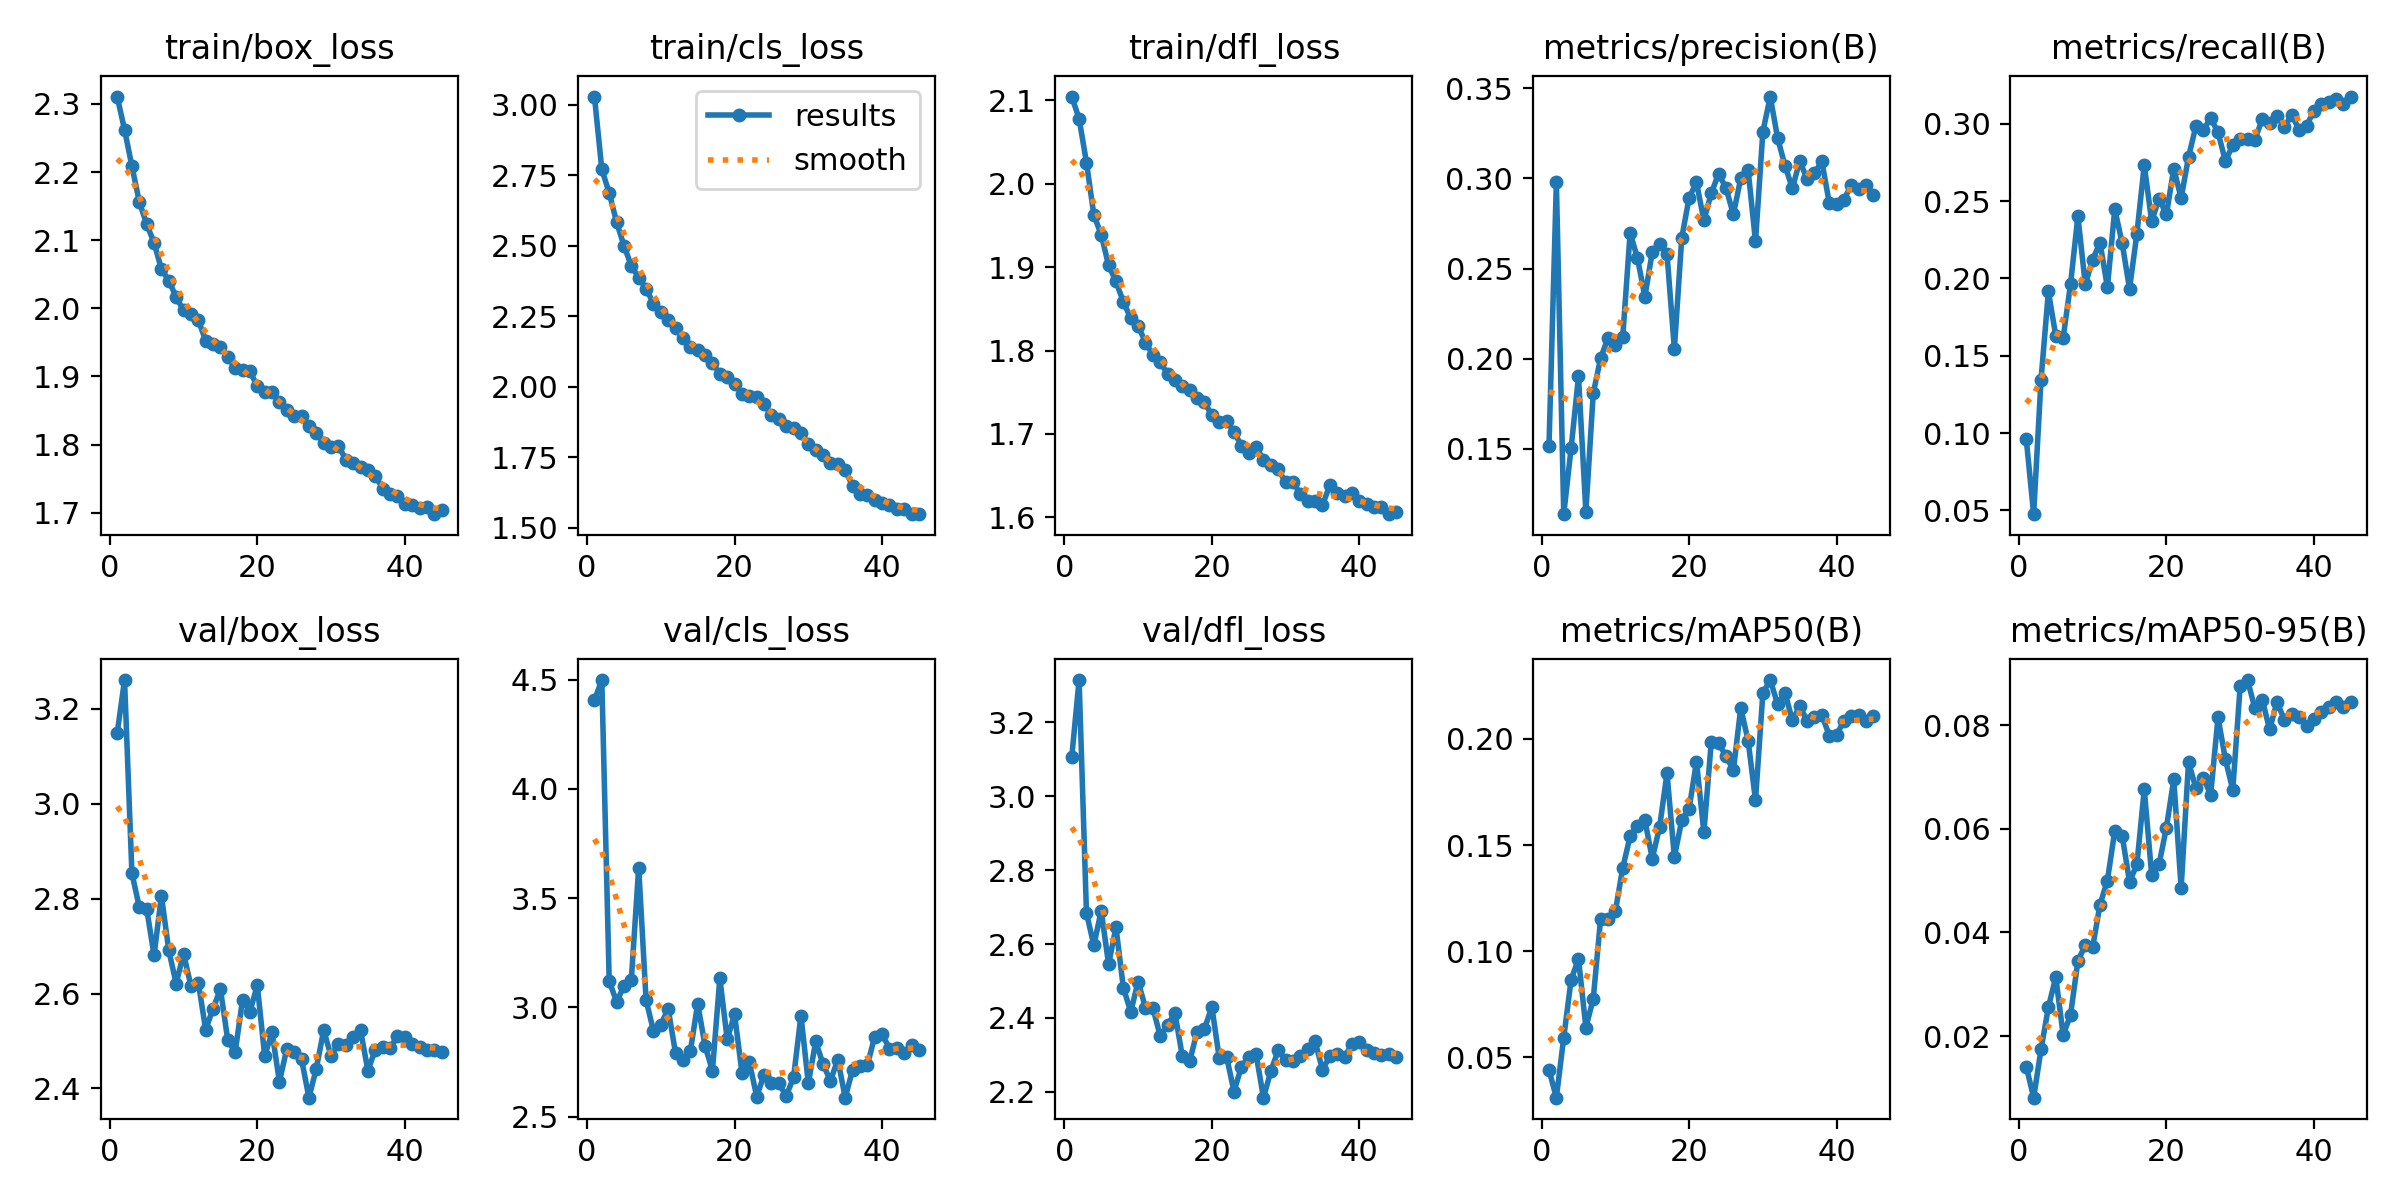

### Train yolov8s
Initialization is the official yolov8s.pt COCO model. No RoadScan 14/17 or published RDD checkpoint is loaded into this candidate.

New https://pypi.org/project/ultralytics/8.4.197 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/run23_team_data/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.

**Training interpretation:** yolov8s completed 47 epochs in 90.6 minutes under the stated budget. Its best validation checkpoint is saved. Training loss alone is not evidence of generalization; compare the next section's validation metrics. Native C2PSA blocks: 0.

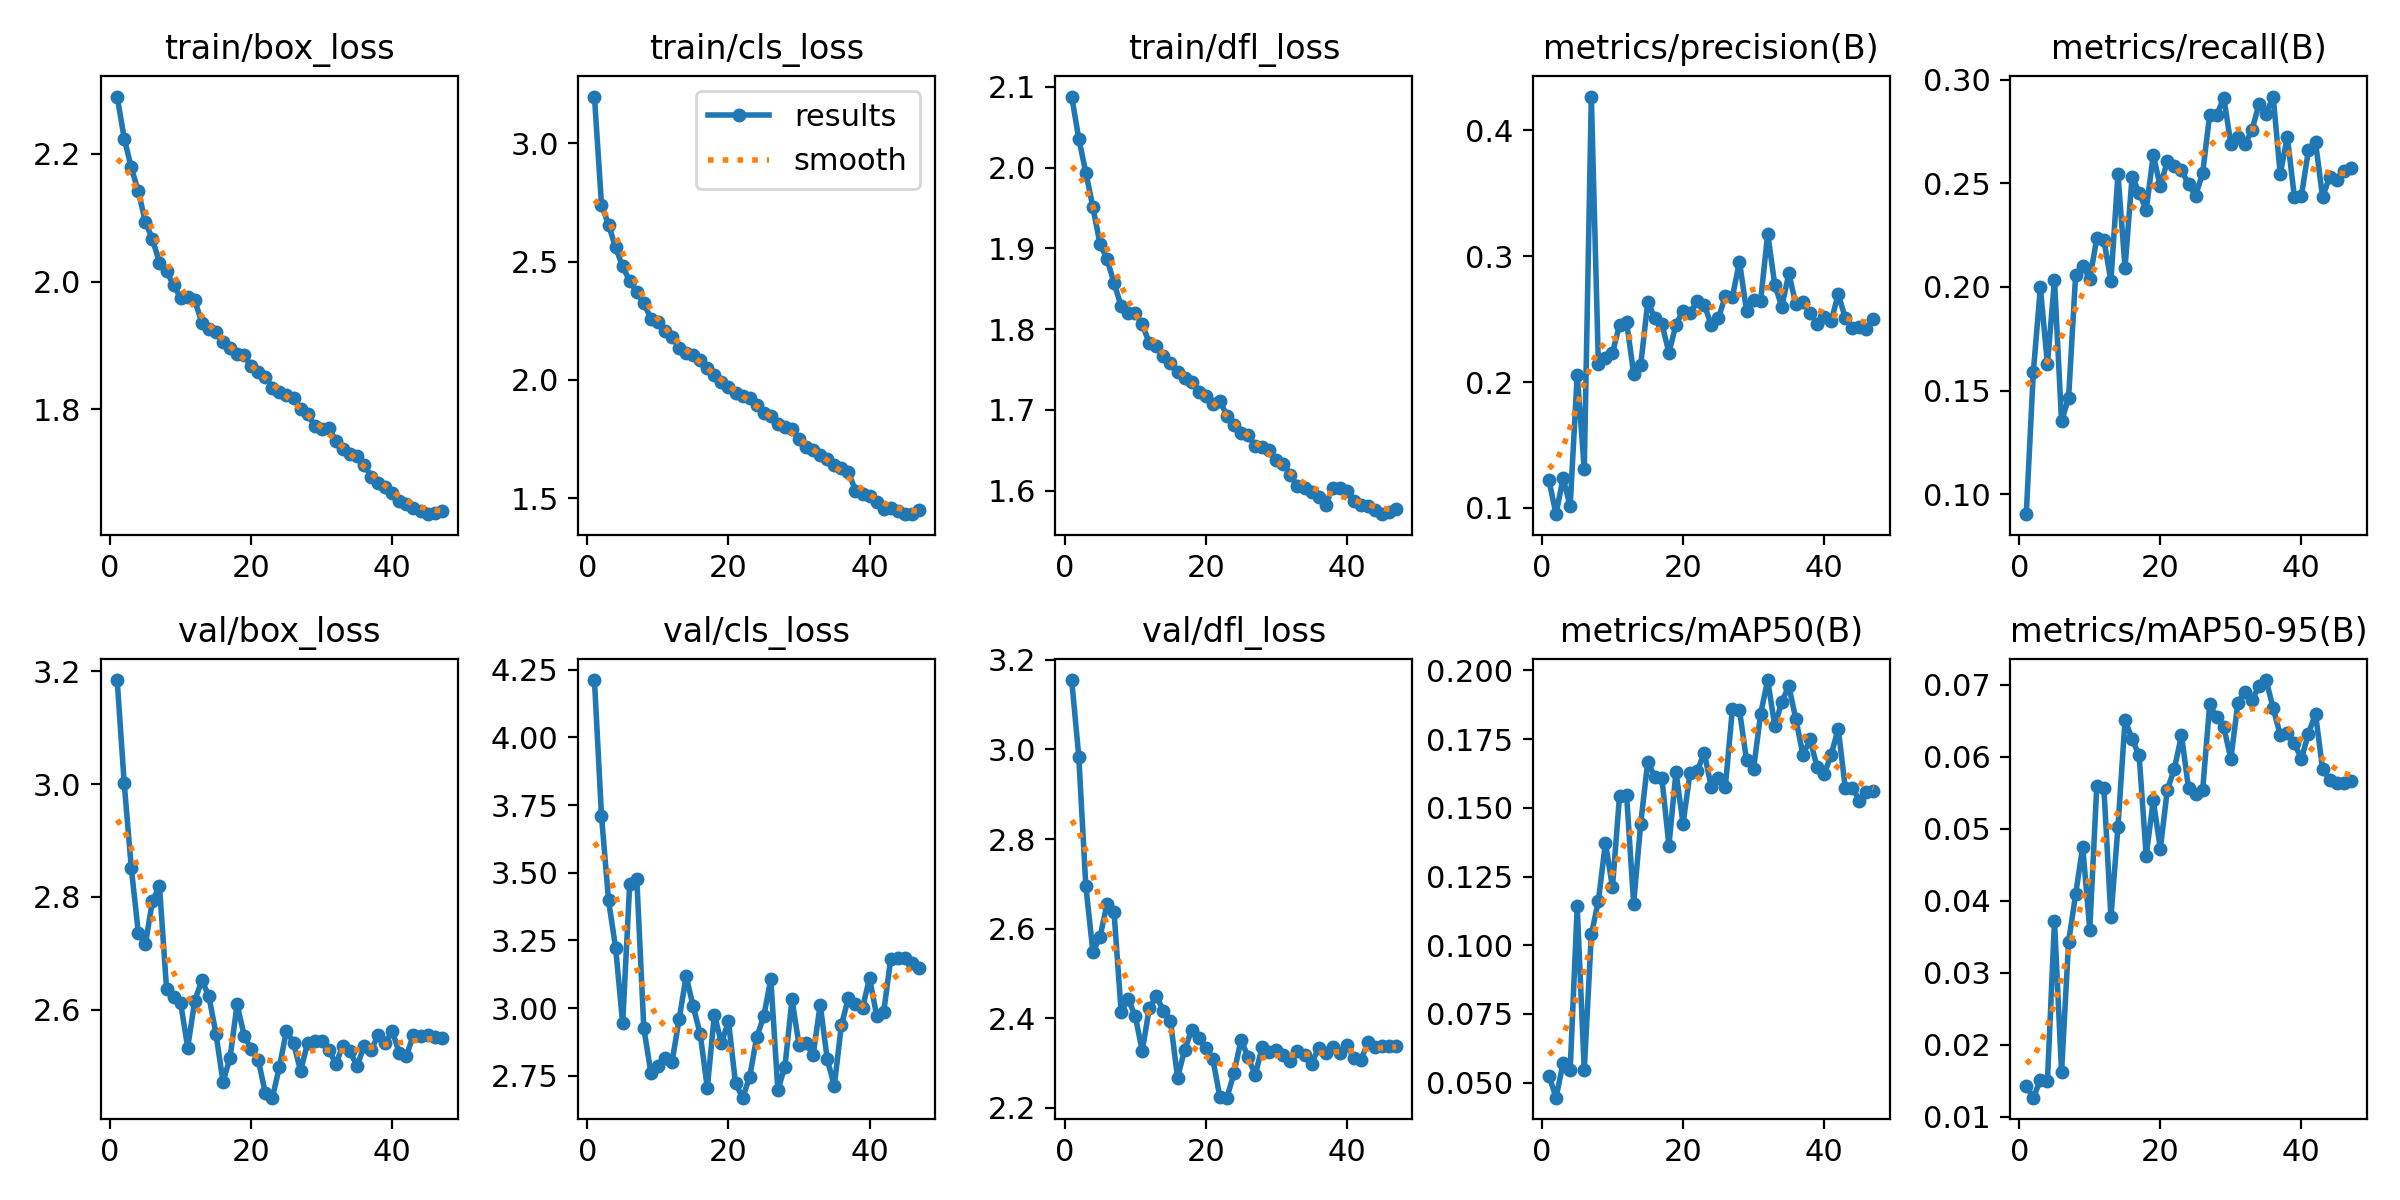

RUN23_TRAINING_COMPLETE [{"candidate": "yolo11s_c2psa", "initial_weights": "yolo11s.pt", "initial_sha256": "85a76fe86dd8afe384648546b56a7a78580c7cb7b404fc595f97969322d502d5", "attention_modules": 1, "completed_epochs": 45, "training_wall_seconds": 5479.239877518, "best_path": "/kaggle/working/run23/training/yolo11s_c2psa/weights/best.pt", "best_sha256": "0bf60fce1b5f91afa5878cd4fd8d6e6fbd46eae18ce024f19546782f46d3c6b0"}, {"candidate": "yolov8s", "initial_weights": "yolov8s.pt", "initial_sha256": "1f47a78bf100391c2a140b7ac73a1caae18c32779be7d310658112f7ac9aa78a", "attention_modules": 0, "completed_epochs": 47, "training_wall_seconds": 5438.461557528, "best_path": "/kaggle/working/run23/training/yolov8s/weights/best.pt", "best_sha256": "c5e15b57c77d17d709ba71f789b1df7abd24ea874adfd8db270a1e1b98e48cac"}]


In [2]:
display(Markdown("## 2. Train two controlled candidates\nFine-tune official COCO-initialized YOLO11s and YOLOv8s on the exact team training set. Both use 640 pixels, AdamW, cosine learning-rate decay, the same training augmentations and seed. Each run allows 60 epochs, patience 15 and a 1.5-hour cap checked at epoch boundaries. Actual completed epochs and training time are recorded; a time cap can make completed schedules differ. Validation selects each checkpoint. US/local data are not used for training or model selection."))
TRAIN=dict(data=str(DATA),epochs=60,time=1.5,patience=15,imgsz=640,batch=16,device=0,workers=2,seed=42,deterministic=True,optimizer='AdamW',lr0=0.001,lrf=0.01,momentum=0.9,weight_decay=0.0005,warmup_epochs=3.0,cos_lr=True,mosaic=0.5,close_mosaic=10,mixup=0.0,copy_paste=0.0,hsv_h=0.015,hsv_s=0.7,hsv_v=0.4,fliplr=0.5,flipud=0.0,degrees=0.0,translate=0.1,scale=0.5,shear=0.0,perspective=0.0,cache=False,amp=True,plots=True,save=True,save_period=10,project=str(OUT/'training'),exist_ok=True,verbose=False)
(OUT/'training_settings.json').write_text(json.dumps(TRAIN,indent=2))
CANDIDATES={'yolo11s_c2psa':'yolo11s.pt','yolov8s':'yolov8s.pt'}
trained={}; training_log=[]
for candidate,initial in CANDIDATES.items():
    display(Markdown(f"### Train {candidate}\nInitialization is the official {initial} COCO model. No RoadScan 14/17 or published RDD checkpoint is loaded into this candidate."))
    net=YOLO(initial)
    attention_count=sum(type(m).__name__=='C2PSA' for m in net.model.modules())
    if candidate=='yolo11s_c2psa': assert attention_count>0, 'Native C2PSA attention missing.'
    sha=hashlib.sha256(Path(initial).read_bytes()).hexdigest()
    start=time.perf_counter()
    net.train(name=candidate,**TRAIN)
    elapsed=time.perf_counter()-start
    run_dir=OUT/'training'/candidate
    best=run_dir/'weights/best.pt'; assert best.is_file(), f'No best checkpoint: {candidate}'
    trained[candidate]=best
    hist=pd.read_csv(run_dir/'results.csv'); hist.columns=hist.columns.str.strip()
    item=dict(candidate=candidate,initial_weights=initial,initial_sha256=sha,attention_modules=attention_count,completed_epochs=len(hist),training_wall_seconds=elapsed,best_path=str(best),best_sha256=hashlib.sha256(best.read_bytes()).hexdigest())
    training_log.append(item); (OUT/'training_log.json').write_text(json.dumps(training_log,indent=2))
    display(Markdown(f"**Training interpretation:** {candidate} completed {len(hist)} epochs in {elapsed/60:.1f} minutes under the stated budget. Its best validation checkpoint is saved. Training loss alone is not evidence of generalization; compare the next section's validation metrics. Native C2PSA blocks: {attention_count}."))
    from IPython.display import Image as DisplayImage
    if (run_dir/'results.png').exists(): display(DisplayImage(filename=str(run_dir/'results.png')))
    del net; gc.collect(); torch.cuda.empty_cache()
print('RUN23_TRAINING_COMPLETE',json.dumps(training_log),flush=True)


## 3. Compare validation performance and freeze a candidate
Evaluate both new checkpoints and historical Runs 14/17 on the same China validation images. Rank only the two new candidates by validation mAP50-95; references remain historical controls. Calibrate the selected candidate's confidence using validation only, then save its weights and settings before opening US evaluation. Precision/recall from the mAP validator are curve operating-point metrics; fixed-confidence box metrics are calculated separately.

### Validation: yolo11s_c2psa
Use unchanged weights, the same 1,977 images, 640 pixels and class-aware matching at IoU 0.5. Historical reference 17 has external RDD pretraining with unknown overlap; it is not a clean architecture control.

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1990.5±487.3 MB/s, size: 79.0 KB)
val: Scanning /kaggle/working/run23_team_data/val/labels.cache... 1977 images, 43 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1977/1977 552.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 124/124 4.3it/s 28.9s
                   all       1977       4650      0.348      0.289      0.227     0.0885
Speed: 1.0ms preprocess, 10.0ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /kaggle/working/run23/validation/yolo11s_c2psa
VALIDATION_PREDICTIONS 500
VALIDATION_PREDICTIONS 1000
VALIDATION_PREDICTIONS 1500


**Validation interpretation:** mAP50=22.7%, mAP50-95=8.9%. At common confidence 0.46: box precision=61.4%, recall=4.5%, micro-F1=8.4%. These are development results, not local-road accuracy.

### Validation: yolov8s
Use unchanged weights, the same 1,977 images, 640 pixels and class-aware matching at IoU 0.5. Historical reference 17 has external RDD pretraining with unknown overlap; it is not a clean architecture control.

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1786.2±781.8 MB/s, size: 78.9 KB)
val: Scanning /kaggle/working/run23_team_data/val/labels.cache... 1977 images, 43 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1977/1977 637.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 124/124 4.5it/s 27.6s
                   all       1977       4650      0.286      0.283      0.194     0.0707
Speed: 1.0ms preprocess, 9.3ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /kaggle/working/run23/validation/yolov8s
VALIDATION_PREDICTIONS 500
VALIDATION_PREDICTIONS 1000
VALIDATION_PREDICTIONS 1500


... (4 outputs left out)

### Validation: reference17_finetuned
Use unchanged weights, the same 1,977 images, 640 pixels and class-aware matching at IoU 0.5. Historical reference 17 has external RDD pretraining with unknown overlap; it is not a clean architecture control.

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1988.5±488.0 MB/s, size: 78.5 KB)
val: Scanning /kaggle/working/run23_team_data/val/labels.cache... 1977 images, 43 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1977/1977 592.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 124/124 4.5it/s 27.9s
                   all       1977       4650      0.917      0.926      0.959      0.658
Speed: 1.0ms preprocess, 9.5ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to /kaggle/working/run23/validation/reference17_finetuned
VALIDATION_PREDICTIONS 500
VALIDATION_PREDICTIONS 1000
VALIDATION_PREDICTIONS 1500


**Validation interpretation:** mAP50=95.9%, mAP50-95=65.8%. At common confidence 0.46: box precision=89.3%, recall=84.5%, micro-F1=86.8%. These are development results, not local-road accuracy.

,model,mAP50,mAP50_95,precision_046,recall_046,micro_f1_046,macro_f1_046,pothole_recall_046,gpu_inference_ms
0,yolo11s_c2psa,0.227326,0.088539,0.614035,0.045161,0.084135,0.120835,0.046809,8.797184
1,yolov8s,0.194063,0.070675,0.514607,0.049247,0.089892,0.118449,0.055319,9.033819
2,reference14_yolo11s,0.227095,0.087325,0.597674,0.055269,0.101181,0.152870,0.110638,8.716320
3,reference17_finetuned,0.959300,0.657899,0.892906,0.844516,0.868037,0.895562,0.965957,9.195739


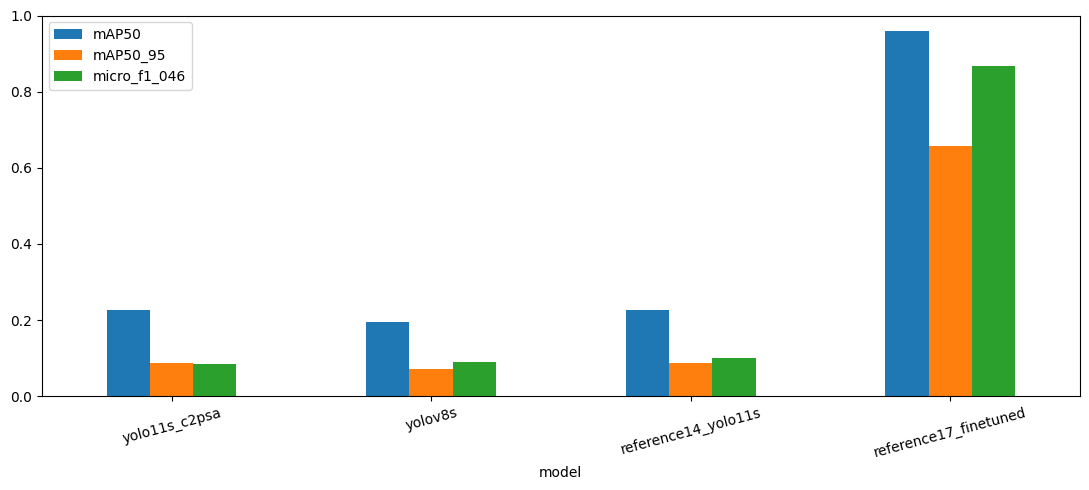

**Selection interpretation:** yolo11s_c2psa is the better NEW candidate on validation mAP50-95. Frozen confidence is 0.001; the 90% validation pothole-recall floor was NOT met. This is not a guarantee for local roads. selected_best.pt and its SHA256/configuration are saved before US evaluation. No local final test has been run.

RUN23_CANDIDATE_FROZEN yolo11s_c2psa 0.001


In [3]:
display(Markdown("## 3. Compare validation performance and freeze a candidate\nEvaluate both new checkpoints and historical Runs 14/17 on the same China validation images. Rank only the two new candidates by validation mAP50-95; references remain historical controls. Calibrate the selected candidate's confidence using validation only, then save its weights and settings before opening US evaluation. Precision/recall from the mAP validator are curve operating-point metrics; fixed-confidence box metrics are calculated separately."))
def box_iou_one(a,bs):
    lo=np.maximum(a[:2],bs[:,:2]); hi=np.minimum(a[2:],bs[:,2:]); inter=np.maximum(hi-lo,0).prod(1)
    return inter/np.maximum((a[2:]-a[:2]).prod()+(bs[:,2:]-bs[:,:2]).prod(1)-inter,1e-9)
def match_detections(ps,g):
    used=set(); out=[]
    for pp in ps[np.argsort(-ps[:,4],kind='stable')]:
        ids=[i for i in range(len(g)) if i not in used and int(g[i,0])==int(pp[5])]; hit=0
        if ids:
            overlaps=box_iou_one(pp[:4],g[ids,1:]); k=int(overlaps.argmax())
            if overlaps[k]>=0.5: used.add(ids[k]); hit=1
        out.append([float(pp[4]),int(pp[5]),hit])
    return out
unit_gt=np.array([[3,0,0,10,10]],dtype=float)
assert [r[2] for r in match_detections(np.array([[0,0,10,10,.9,3],[0,0,10,10,.8,3]]),unit_gt)]==[1,0]
assert match_detections(np.array([[0,0,10,10,.9,0]]),unit_gt)[0][2]==0
assert match_detections(np.empty((0,6)),unit_gt)==[]
def load_truth(image_dir,label_dir):
    paths=sorted(p for p in Path(image_dir).glob('*') if p.suffix.lower() in ['.jpg','.jpeg','.png'])
    truth_map={}; supports=np.zeros(4,dtype=int)
    for ip in paths:
        with Image.open(ip) as im: w,h=im.size
        lp=Path(label_dir)/(ip.stem+'.txt'); assert lp.exists(), lp
        vals=[]
        for line in lp.read_text().splitlines():
            if not line.strip(): continue
            vv=list(map(float,line.split())); assert len(vv)==5 and np.isfinite(vv).all()
            c,x,y,bw,bh=vv; assert c==int(c) and 0<=c<4 and bw>0 and bh>0
            assert min(x-bw/2,y-bh/2)>=-0.001 and max(x+bw/2,y+bh/2)<=1.001
            vals.append([c,(x-bw/2)*w,(y-bh/2)*h,(x+bw/2)*w,(y+bh/2)*h]); supports[int(c)]+=1
        truth_map[ip.name]=np.asarray(vals,dtype=float).reshape(-1,5)
    return paths,truth_map,supports
val_paths,val_truth,val_support=load_truth(ROOT/'val/images',ROOT/'val/labels')
def fixed_metrics(recs,supports,threshold):
    kept=recs[recs[:,0]>=threshold]; rows=[]
    for c,code in enumerate(CLASSES):
        cc=kept[kept[:,1]==c]; tp=int(cc[:,2].sum()); fp=len(cc)-tp; fn=int(supports[c])-tp
        rows.append(dict(cls=code,TP=tp,FP=fp,FN=fn,precision=tp/max(tp+fp,1),recall=tp/max(tp+fn,1),f1=2*tp/max(2*tp+fp+fn,1),support=int(supports[c])))
    tp=sum(x['TP'] for x in rows); fp=sum(x['FP'] for x in rows); fn=sum(x['FN'] for x in rows)
    return dict(confidence=float(threshold),box_precision=tp/max(tp+fp,1),box_recall=tp/max(tp+fn,1),box_micro_f1=2*tp/max(2*tp+fp+fn,1),box_macro_f1=float(np.mean([x['f1'] for x in rows])),pothole_recall=rows[3]['recall'],TP=tp,FP=fp,FN=fn,per_class=rows)
def predictions_to_records(net,image_dir,truth_map):
    rows=[]; speeds=[]
    for i,rr in enumerate(net.predict(source=str(image_dir),imgsz=640,conf=0.001,iou=0.7,max_det=300,device=0,stream=True,verbose=False),1):
        rows.extend(match_detections(rr.boxes.data.cpu().numpy(),truth_map[Path(rr.path).name])); speeds.append(rr.speed['inference'])
        if i%500==0: print('VALIDATION_PREDICTIONS',i,flush=True)
    return np.asarray(rows,dtype=float).reshape(-1,3),float(np.mean(speeds))
ref14=INPUT/'notebooks/rimasabunasser/14-roadscan-team-v2-training/artifacts_team_v2/best.pt'
ref17=INPUT/'notebooks/rimasabunasser/17-roadscan-gentle-finetuning/run17_model_comparison/run17_best_finetuned.pt'
assert ref14.is_file() and ref17.is_file()
CHECKPOINTS={**trained,'reference14_yolo11s':ref14,'reference17_finetuned':ref17}
val_rows=[]; val_records={}
for label,weight in CHECKPOINTS.items():
    display(Markdown(f"### Validation: {label}\nUse unchanged weights, the same 1,977 images, 640 pixels and class-aware matching at IoU 0.5. Historical reference 17 has external RDD pretraining with unknown overlap; it is not a clean architecture control."))
    net=YOLO(str(weight)); assert [net.names[i] for i in range(4)]==CLASSES
    metric=net.val(data=str(DATA),split='val',imgsz=640,batch=16,device=0,workers=2,conf=0.001,iou=0.7,max_det=300,plots=True,project=str(OUT/'validation'),name=label,exist_ok=True,verbose=False)
    recs,ms=predictions_to_records(net,ROOT/'val/images',val_truth); val_records[label]=recs
    np.savez_compressed(OUT/f'{label}_validation_detections.npz',records=recs,support=val_support)
    op=fixed_metrics(recs,val_support,0.46)
    row=dict(model=label,mAP50=float(metric.box.map50),mAP50_95=float(metric.box.map),precision_046=op['box_precision'],recall_046=op['box_recall'],micro_f1_046=op['box_micro_f1'],macro_f1_046=op['box_macro_f1'],pothole_recall_046=op['pothole_recall'],gpu_inference_ms=ms)
    val_rows.append(row); (OUT/f'{label}_validation.json').write_text(json.dumps(dict(summary=row,operational_at_046=op,weights_sha256=hashlib.sha256(weight.read_bytes()).hexdigest()),indent=2))
    display(Markdown(f"**Validation interpretation:** mAP50={row['mAP50']:.1%}, mAP50-95={row['mAP50_95']:.1%}. At common confidence 0.46: box precision={op['box_precision']:.1%}, recall={op['box_recall']:.1%}, micro-F1={op['box_micro_f1']:.1%}. These are development results, not local-road accuracy."))
    del net; gc.collect(); torch.cuda.empty_cache()
validation=pd.DataFrame(val_rows); validation.to_csv(OUT/'validation_comparison.csv',index=False); display(validation)
import matplotlib.pyplot as plt
validation.set_index('model')[['mAP50','mAP50_95','micro_f1_046']].plot.bar(rot=15,ylim=(0,1),figsize=(11,5)); plt.tight_layout(); plt.savefig(OUT/'validation_comparison.png'); plt.show()
new_rows=[r for r in val_rows if r['model'] in trained]
selected=max(new_rows,key=lambda r:(r['mAP50_95'],-r['gpu_inference_ms']))['model']
sweep=[fixed_metrics(val_records[selected],val_support,t) for t in [0.001]+[round(i/100,2) for i in range(1,96)]]
feasible=[r for r in sweep if r['pothole_recall']>=0.90]
if feasible: calibrated=max(feasible,key=lambda r:(r['box_macro_f1'],r['pothole_recall'],r['confidence']))
else: calibrated=max(sweep,key=lambda r:(r['pothole_recall'],r['box_macro_f1'],r['confidence']))
(OUT/'confidence_sweep.json').write_text(json.dumps(sweep,indent=2))
pd.DataFrame([{k:v for k,v in r.items() if k!='per_class'} for r in sweep]).to_csv(OUT/'confidence_sweep.csv',index=False)
threshold=calibrated['confidence']; selected_path=OUT/'selected_best.pt'; shutil.copy2(trained[selected],selected_path)
config=dict(candidate=selected,weights_file=selected_path.name,weights_sha256=hashlib.sha256(selected_path.read_bytes()).hexdigest(),class_names=CLASSES,imgsz=640,confidence=threshold,nms_iou=0.7,max_det=300,matching_iou=0.5,selection_source='China validation only',validation_mAP50_95=next(r['mAP50_95'] for r in val_rows if r['model']==selected),pothole_recall_floor_met=bool(feasible),validation_operating_metrics=calibrated,local_images_used=False,local_final_test_locked=True,project_adoption='candidate only; no automatic replacement of run17',local_evaluation_performed=False)
(OUT/'frozen_model_config.json').write_text(json.dumps(config,indent=2))
POLICY['frozen_candidate']=selected; POLICY['frozen_confidence']=threshold
(OUT/'experiment_policy.json').write_text(json.dumps(POLICY,indent=2))
display(Markdown(f"**Selection interpretation:** {selected} is the better NEW candidate on validation mAP50-95. Frozen confidence is {threshold}; the 90% validation pothole-recall floor was {'met' if feasible else 'NOT met'}. This is not a guarantee for local roads. selected_best.pt and its SHA256/configuration are saved before US evaluation. No local final test has been run."))
print('RUN23_CANDIDATE_FROZEN',selected,threshold,flush=True)


## 4. Fixed RDD US comparison after model/configuration freeze
Now evaluate the frozen candidate and historical references on RDD US with identical inference settings. This test comparison is descriptive and does not change candidate selection, confidence or training. Previous project work already examined US results, so it is not an unseen final test. The 190 local photographs remain excluded.

US_AUDITED 1000 / 4805
US_AUDITED 2000 / 4805
US_AUDITED 3000 / 4805
US_AUDITED 4000 / 4805
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1578.2±735.2 MB/s, size: 66.3 KB)
val: Scanning /kaggle/working/run23_team_data/test_US/labels... 4805 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4805/4805 1.2Kit/s 4.0s
val: New cache created: /kaggle/working/run23_team_data/test_US/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 301/301 4.3it/s 1:10
                   all       4805      11014      0.494      0.432      0.422      0.219
Speed: 0.9ms preprocess, 9.9ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /kaggle/working/run23/us_test/yolo11s_c2psa
VALIDATION_PREDICTIONS 500
VALIDATION_PREDICTIONS 1000
VALIDATION_PREDICT

**US interpretation (yolo11s_c2psa):** 4805 images; mAP50=42.2%, mAP50-95=21.9%; at frozen common confidence 0.001, precision=1.7%, recall=92.7%, micro-F1=3.4%. These results do not alter selection and do not establish performance on local roads.

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1879.0±553.2 MB/s, size: 67.6 KB)
val: Scanning /kaggle/working/run23_team_data/test_US/labels.cache... 4805 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4805/4805 1.7Git/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 301/301 4.4it/s 1:09
                   all       4805      11014      0.503      0.473      0.446       0.24
Speed: 0.9ms preprocess, 9.8ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /kaggle/working/run23/us_test/reference14_yolo11s
VALIDATION_PREDICTIONS 500
VALIDATION_PREDICTIONS 1000
VALIDATION_PREDICTIONS 1500
VALIDATION_PREDICTIONS 2000
VALIDATION_PREDICTIONS 2500
VALIDATION_PREDICTIONS 3000
VALIDATION_PREDICTIONS 3500
VALIDATION_PREDICTIONS 4000
VALIDAT

**US interpretation (reference14_yolo11s):** 4805 images; mAP50=44.6%, mAP50-95=24.0%; at frozen common confidence 0.001, precision=1.8%, recall=93.7%, micro-F1=3.6%. These results do not alter selection and do not establish performance on local roads.

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1563.5±527.0 MB/s, size: 74.2 KB)
val: Scanning /kaggle/working/run23_team_data/test_US/labels.cache... 4805 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4805/4805 1.6Git/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 301/301 4.5it/s 1:07
                   all       4805      11014      0.697      0.759      0.764      0.497
Speed: 0.9ms preprocess, 9.5ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /kaggle/working/run23/us_test/reference17_finetuned
VALIDATION_PREDICTIONS 500
VALIDATION_PREDICTIONS 1000
VALIDATION_PREDICTIONS 1500
VALIDATION_PREDICTIONS 2000
VALIDATION_PREDICTIONS 2500
VALIDATION_PREDICTIONS 3000
VALIDATION_PREDICTIONS 3500
VALIDATION_PREDICTIONS 4000
VALIDAT

**US interpretation (reference17_finetuned):** 4805 images; mAP50=76.4%, mAP50-95=49.7%; at frozen common confidence 0.001, precision=4.1%, recall=98.7%, micro-F1=7.9%. These results do not alter selection and do not establish performance on local roads.

,model,mAP50,mAP50_95,confidence,precision,recall,micro_f1,macro_f1,gpu_inference_ms
0,yolo11s_c2psa,0.422469,0.218595,0.001,0.017406,0.926730,0.034171,0.025496,9.232410
1,reference14_yolo11s,0.446388,0.240120,0.001,0.018398,0.936989,0.036087,0.027054,9.254489
2,reference17_finetuned,0.764357,0.497263,0.001,0.041346,0.987017,0.079367,0.079347,9.526638


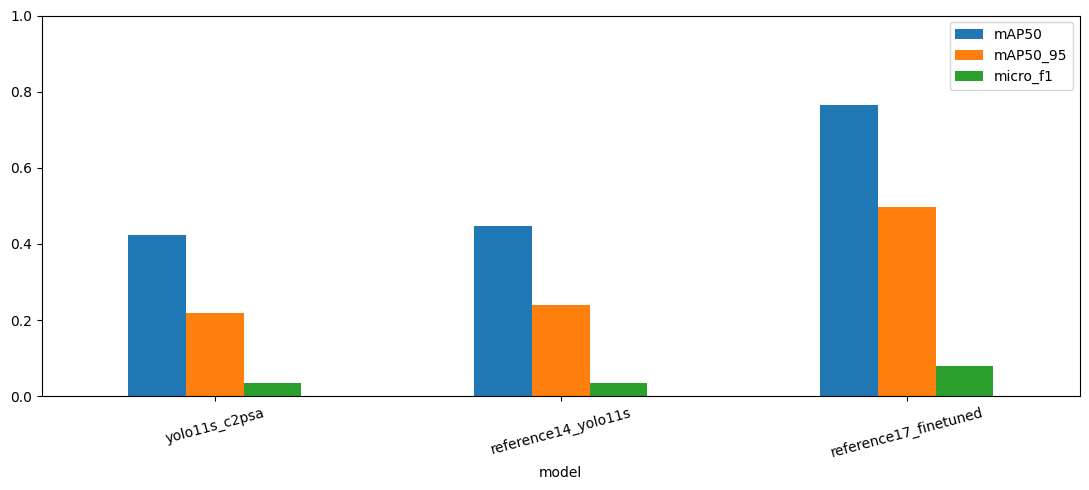

# Run 23: controlled YOLO comparison

| model                 |    mAP50 |   mAP50_95 |   precision_046 |   recall_046 |   micro_f1_046 |   macro_f1_046 |   pothole_recall_046 |   gpu_inference_ms |
|:----------------------|---------:|-----------:|----------------:|-------------:|---------------:|---------------:|---------------------:|-------------------:|
| yolo11s_c2psa         | 0.227326 |  0.0885386 |        0.614035 |    0.0451613 |      0.0841346 |       0.120835 |            0.0468085 |            8.79718 |
| yolov8s               | 0.194063 |  0.0706751 |        0.514607 |    0.0492473 |      0.0898921 |       0.118449 |            0.0553191 |            9.03382 |
| reference14_yolo11s   | 0.227095 |  0.0873246 |        0.597674 |    0.0552688 |      0.101181  |       0.15287  |            0.110638  |            8.71632 |
| reference17_finetuned | 0.9593   |  0.657899  |        0.892906 |    0.844516  |      0.868037  |       0.895562 |            0.965957  |            9.19574 |

## Fixed US comparison

| model                 |    mAP50 |   mAP50_95 |   confidence |   precision |   recall |   micro_f1 |   macro_f1 |   gpu_inference_ms |
|:----------------------|---------:|-----------:|-------------:|------------:|---------:|-----------:|-----------:|-------------------:|
| yolo11s_c2psa         | 0.422469 |   0.218595 |        0.001 |   0.0174064 | 0.92673  |  0.0341709 |  0.0254961 |            9.23241 |
| reference14_yolo11s   | 0.446388 |   0.24012  |        0.001 |   0.018398  | 0.936989 |  0.0360874 |  0.027054  |            9.25449 |
| reference17_finetuned | 0.764357 |   0.497263 |        0.001 |   0.0413459 | 0.987017 |  0.0793672 |  0.0793466 |            9.52664 |

Selected NEW candidate: yolo11s_c2psa. Official COCO initialization only. YOLO11s includes native C2PSA attention; Run14 also had this module. This is not a causal attention ablation. Training schedules can end at different epochs because each has the same time cap. No local images were attached or accessed. US scores do not alter model selection. Validation scores are development estimates, single-seed only. Run17 external-pretraining overlap is unknown.


RUN23_COMPLETE_LOCAL_TEST_STILL_LOCKED yolo11s_c2psa 0.001


In [4]:
display(Markdown("## 4. Fixed RDD US comparison after model/configuration freeze\nNow evaluate the frozen candidate and historical references on RDD US with identical inference settings. This test comparison is descriptive and does not change candidate selection, confidence or training. Previous project work already examined US results, so it is not an unseen final test. The 190 local photographs remain excluded."))
assert (OUT/'frozen_model_config.json').is_file()
rdd=INPUT/'datasets/sarvii7/roadscan-yolo/RoadScan_yolo'
assert (rdd/'test_US/images').is_dir() and (rdd/'test_US/labels').is_dir()
us_images=sorted(p for p in (rdd/'test_US/images').glob('*') if p.suffix.lower() in ['.jpg','.jpeg','.png'])
assert us_images, 'RDD US test is missing.'
for folder in ['images','labels']: (ROOT/'test_US'/folder).mkdir(parents=True,exist_ok=True)
us_jobs=[('test_US',p.stem,p,rdd/'test_US/labels'/(p.stem+'.txt')) for p in us_images]
us_rows=[]
with ThreadPoolExecutor(max_workers=4) as pool:
    for i,row in enumerate(pool.map(audit_image,us_jobs),1):
        us_rows.append(row)
        if i%1000==0: print('US_AUDITED',i,'/',len(us_jobs),flush=True)
us_manifest=pd.DataFrame(us_rows); us_manifest.to_csv(OUT/'us_test_manifest.csv',index=False)
assert not set(us_manifest.pixel_sha256).intersection(set(manifest.pixel_sha256)), 'Exact US/training-validation pixel overlap: stop US evaluation.'
US_DATA=ROOT/'data_us.yaml'; US_DATA.write_text(yaml.safe_dump(dict(path=str(ROOT),train='train/images',val='val/images',test='test_US/images',names=CLASSES)))
us_paths,us_truth,us_support=load_truth(ROOT/'test_US/images',ROOT/'test_US/labels')
us_results=[]
for label,weight in {selected:selected_path,'reference14_yolo11s':ref14,'reference17_finetuned':ref17}.items():
    net=YOLO(str(weight))
    m=net.val(data=str(US_DATA),split='test',imgsz=640,batch=16,device=0,workers=2,conf=0.001,iou=0.7,max_det=300,plots=True,project=str(OUT/'us_test'),name=label,exist_ok=True,verbose=False)
    recs,ms=predictions_to_records(net,ROOT/'test_US/images',us_truth)
    op=fixed_metrics(recs,us_support,threshold)
    row=dict(model=label,mAP50=float(m.box.map50),mAP50_95=float(m.box.map),confidence=threshold,precision=op['box_precision'],recall=op['box_recall'],micro_f1=op['box_micro_f1'],macro_f1=op['box_macro_f1'],gpu_inference_ms=ms)
    us_results.append(dict(summary=row,per_class=op['per_class']))
    (OUT/f'{label}_us_test.json').write_text(json.dumps(us_results[-1],indent=2))
    display(Markdown(f"**US interpretation ({label}):** {len(us_paths)} images; mAP50={row['mAP50']:.1%}, mAP50-95={row['mAP50_95']:.1%}; at frozen common confidence {threshold}, precision={row['precision']:.1%}, recall={row['recall']:.1%}, micro-F1={row['micro_f1']:.1%}. These results do not alter selection and do not establish performance on local roads."))
    del net; gc.collect(); torch.cuda.empty_cache()
us_table=pd.DataFrame([x['summary'] for x in us_results]); us_table.to_csv(OUT/'us_test_comparison.csv',index=False); display(us_table)
us_table.set_index('model')[['mAP50','mAP50_95','micro_f1']].plot.bar(rot=15,ylim=(0,1),figsize=(11,5)); plt.tight_layout(); plt.savefig(OUT/'us_test_comparison.png'); plt.show()
combined=dict(policy=POLICY,training=training_log,validation=val_rows,frozen_configuration=config,us_test=us_results,local_images_used=False,local_final_test_performed=False)
(OUT/'all_results.json').write_text(json.dumps(combined,indent=2))
readme='# Run 23: controlled YOLO comparison\n\n'+validation.to_markdown(index=False)+'\n\n## Fixed US comparison\n\n'+us_table.to_markdown(index=False)+'\n\nSelected NEW candidate: '+selected+'. Official COCO initialization only. YOLO11s includes native C2PSA attention; Run14 also had this module. This is not a causal attention ablation. Training schedules can end at different epochs because each has the same time cap. No local images were attached or accessed. US scores do not alter model selection. Validation scores are development estimates, single-seed only. Run17 external-pretraining overlap is unknown.\n'
(OUT/'README_RESULTS.md').write_text(readme); display(Markdown(readme))
gate='''# Local final-test gate

The 190 local images were not attached, read, trained on or scored in Run23. Only RDD train/China validation influenced this experiment. The original local evaluation of old models remains a historical result and prior exposure must be disclosed.

Before any later local evaluation: finish all RDD development, freeze the exact model SHA256 from frozen_model_config.json, confidence, image size, NMS and max_det; archive the validation selection decision. Confirm class-order compatibility from labels and checkpoint metadata without examining local model predictions. Run the final local evaluation once on the frozen pipeline and report all classes plus healthy-road false positives. Do not choose among candidates or tune parameters from local results. No automatic local download/evaluation is included here.

Do not claim that these previously inspected images became a new fully independent test set merely because new weights were trained.
'''
(OUT/'LOCAL_FINAL_TEST_GATE.md').write_text(gate)
shutil.make_archive('/kaggle/working/run23_results','zip',OUT)
print('RUN23_COMPLETE_LOCAL_TEST_STILL_LOCKED',selected,threshold,flush=True)
